# Задача: Отобразить высокомерные данные $X ∈ ℝ^D$ в низкомерное пространство $Y ∈ ℝ^d (d=2,3)$ так, чтобы сохранить структуру соседства.

    1. Вероятностная постановка задачи


Задача: Отобразить высокомерные данные X ∈ ℝ^D в низкомерное пространство Y ∈ ℝ^d (d=2,3)
так, чтобы сохранить структуру соседства.


        - Вероятности в исходном пространстве

Гауссово ядро для измерения сходства:

$
p_{j|i} = exp(-||x_i - x_j||^2 / (2σ_i^2)) / Σ_{k≠i} exp(-||x_i - x_k||^2 / (2σ_i^2))$

Симметризация вероятностей:

$
p_{ij} = (p_{j|i} + p_{i|j}) / (2n)$

Перплексия (perplexity) как гиперпараметр:

$
Perp(P_i) = 2^{H(P_i)}, $

где $H(P_i) = -Σ_j p_{j|i} log₂ p_{j|i}$

        - Вероятности в целевом пространстве

Распределение Стьюдента с одной степенью свободы:

$
q_{ij} = (1 + ||y_i - y_j||^2)^{-1} / Σ_{k≠l} (1 + ||y_k - y_l||^2)^{-1}$

Преимущества t-распределения:

       * Тяжелые хвосты

       * Устойчивость к проклятию размерности

       * Улучшенное разделение кластеров

       * Функция стоимости (KL-дивергенция)

$C(Y) = KL(P||Q) = Σ_i Σ_j p_{ij} log(p_{ij} / q_{ij})$

    2. Оптимизация функции стоимости

        2.1. Градиент функции стоимости

$∂C/∂y_i = 4 Σ_j (p_{ij} - q_{ij})(y_i - y_j)(1 + ||y_i - y_j||^2)^{-1}$

       2.2. Методы оптимизации

Градиентный спуск с моментумом:

$Y^{(t)} = Y^{(t-1)} + η ∂C/∂Y + α(t)(Y^{(t-1)} - Y^{(t-2)})$


Раннее преувеличение (early exaggeration):


$p_{ij} ← p_{ij} × 4 (первые 100 итераций)$


Адаптивное обучение (adaptive learning rate)

        2.3. Сложности оптимизации

            - Невыпуклость функции стоимости

            - Локальные минимумы

            - Чувствительность к начальной инициализации

            - Вычислительная сложность O(n²)

Импорт библиотек

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split


# Задание

1. Провести исследование влияния гиперпараметров на результаты кластеризации с T-SNE
2. Сравнить с PCA
   
Использовать 2 датасета - стандартного типа Ирис или Цифры, и своего. Не забываем про нормировку и eda в целом

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# путь к файлу
path = "/content/drive/MyDrive/MAGA/clustering_(2_semestr)/practice/phones_usage.csv"

df = pd.read_csv(path)
df.head()

,transaction_id,user_id,age,gender,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,stress_level,academic_work_impact,addiction_level,addicted_label
0,TXN00001,U00001,21,Male,3.23,2.01,0.89,4.55,7.55,248,154,3.95,Medium,Yes,NaN,0
1,TXN00002,U00002,24,Other,5.09,3.81,2.24,4.44,7.66,127,71,6.71,Medium,Yes,NaN,0
2,TXN00003,U00003,31,Other,6.06,1.36,3.83,2.35,4.92,44,106,8.68,High,No,Mild,0
3,TXN00004,U00004,32,Other,7.83,5.85,1.51,3.54,8.23,178,107,9.77,High,Yes,Moderate,1
4,TXN00005,U00005,25,Male,9.96,5.92,3.42,5.27,6.21,136,177,12.55,Low,No,Severe,1


In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7500 entries, 0 to 7499
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   transaction_id           7500 non-null   object 
 1   user_id                  7500 non-null   object 
 2   age                      7500 non-null   int64  
 3   gender                   7500 non-null   object 
 4   daily_screen_time_hours  7500 non-null   float64
 5   social_media_hours       7500 non-null   float64
 6   gaming_hours             7500 non-null   float64
 7   work_study_hours         7500 non-null   float64
 8   sleep_hours              7500 non-null   float64
 9   notifications_per_day    7500 non-null   int64  
 10  app_opens_per_day        7500 non-null   int64  
 11  weekend_screen_time      7500 non-null   float64
 12  stress_level             7500 non-null   object 
 13  academic_work_impact     7500 non-null   object 
 14  addiction_level         

In [ ]:
df['addiction_level'].fillna('Mild', inplace=True)

/tmp/ipykernel_1832/249691183.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['addiction_level'].fillna('Mild', inplace=True)


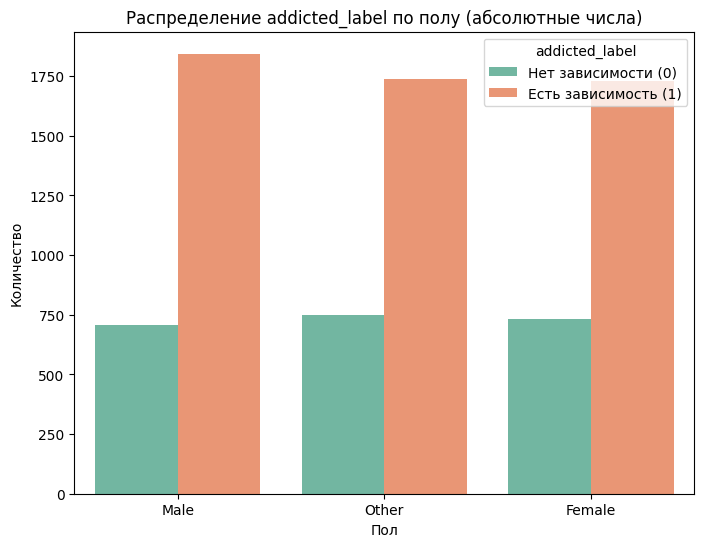

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.countplot(data=df, x='gender', hue='addicted_label', palette='Set2')
plt.title('Распределение addicted_label по полу (абсолютные числа)')
plt.xlabel('Пол')
plt.ylabel('Количество')
plt.legend(title='addicted_label', labels=['Нет зависимости (0)', 'Есть зависимость (1)'])
plt.show()

In [ ]:
df['addicted_label'].value_counts()

,count
addicted_label,
1,5308
0,2192


In [ ]:
df = df.drop('gender', axis=1)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7500 entries, 0 to 7499
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   transaction_id           7500 non-null   object 
 1   user_id                  7500 non-null   object 
 2   age                      7500 non-null   int64  
 3   daily_screen_time_hours  7500 non-null   float64
 4   social_media_hours       7500 non-null   float64
 5   gaming_hours             7500 non-null   float64
 6   work_study_hours         7500 non-null   float64
 7   sleep_hours              7500 non-null   float64
 8   notifications_per_day    7500 non-null   int64  
 9   app_opens_per_day        7500 non-null   int64  
 10  weekend_screen_time      7500 non-null   float64
 11  stress_level             7500 non-null   object 
 12  academic_work_impact     7500 non-null   object 
 13  addiction_level          7500 non-null   object 
 14  addicted_label          

In [ ]:
stress_map = {'Low': 0, 'Medium': 1, 'High': 2}

df['stress_map'] = df['stress_level'].map(stress_map)

In [ ]:
academic_work_impact_map = {'No': 0, 'Yes': 1}

df['academic_work_impact_map'] = df['academic_work_impact'].map(academic_work_impact_map)

In [ ]:
addiction_level_map = {'Mild': 0, 'Moderate': 1, 'Severe': 2}

df['addiction_level_map'] = df['addiction_level'].map(addiction_level_map)

In [ ]:
df = df.drop(['transaction_id', 'user_id', 'stress_level', 'academic_work_impact', 'addiction_level'], axis=1)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7500 entries, 0 to 7499
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       7500 non-null   int64  
 1   daily_screen_time_hours   7500 non-null   float64
 2   social_media_hours        7500 non-null   float64
 3   gaming_hours              7500 non-null   float64
 4   work_study_hours          7500 non-null   float64
 5   sleep_hours               7500 non-null   float64
 6   notifications_per_day     7500 non-null   int64  
 7   app_opens_per_day         7500 non-null   int64  
 8   weekend_screen_time       7500 non-null   float64
 9   addicted_label            7500 non-null   int64  
 10  stress_map                7500 non-null   int64  
 11  academic_work_impact_map  7500 non-null   int64  
 12  addiction_level_map       7500 non-null   int64  
dtypes: float64(6), int64(7)
memory usage: 761.8 KB


В данных нет пропусков, типы данных числовые: целые и вещественные. Целевая переменная - addicted_label

In [ ]:
from sklearn.datasets import load_digits

digits = load_digits()
X = digits.data
y = digits.target

print(X.shape, y.shape)

(1797, 64) (1797,)


Разделение данных на фичи и целевую переменную

In [ ]:
target = 'addicted_label'
X_phones = df.drop(target, axis=1)
y_phones = df[target]

print(X_phones.shape, y_phones.shape)

(7500, 12) (7500,)


Нормировка

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_phones_scaled = scaler.fit_transform(X_phones)


Доля объяснённой дисперсии: [0.12033916 0.09561054] Суммарно: 0.21594970500832789


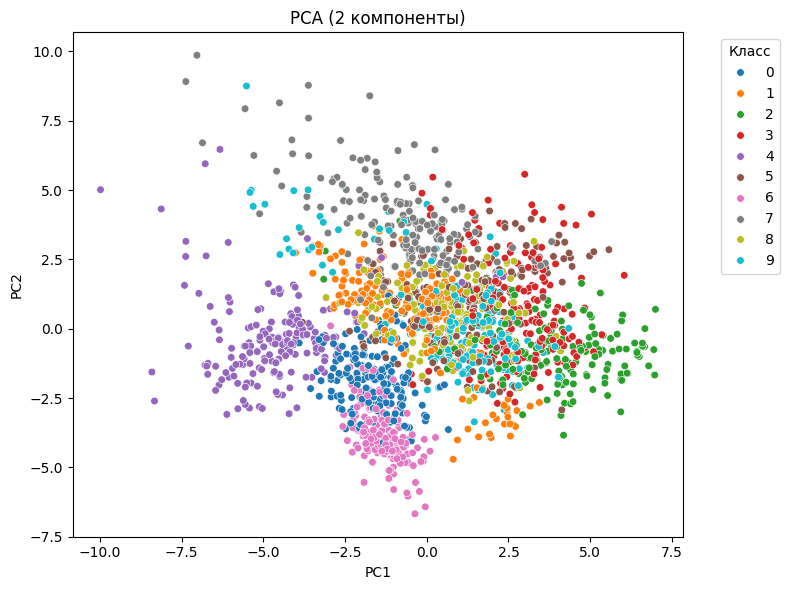

In [ ]:
# датасет чисел
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print("Доля объяснённой дисперсии:", pca.explained_variance_ratio_,
      "Суммарно:", pca.explained_variance_ratio_.sum())

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y, palette="tab10", s=30)
plt.title("PCA (2 компоненты)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(title="Класс", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()


Доля объяснённой дисперсии: [0.19752384 0.09794315] Суммарно: 0.29546699289133116


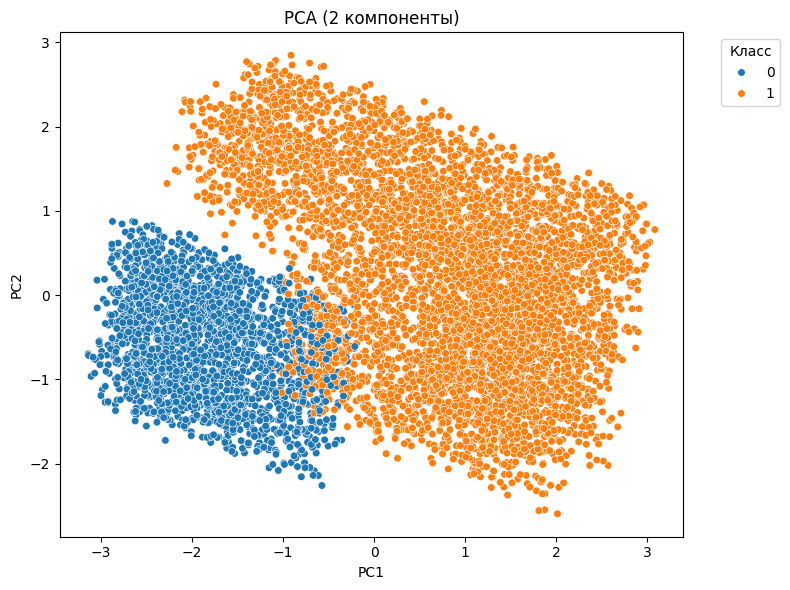

In [ ]:
# датасет телефонов
pca_phones = PCA(n_components=2, random_state=42)
X_phones_pca = pca_phones.fit_transform(X_phones_scaled)

print("Доля объяснённой дисперсии:", pca_phones.explained_variance_ratio_,
      "Суммарно:", pca_phones.explained_variance_ratio_.sum())

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_phones_pca[:, 0], y=X_phones_pca[:, 1], hue=y_phones, palette="tab10", s=30)
plt.title("PCA (2 компоненты)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(title="Класс", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()
plt.show()

TSNE 2 компоненты

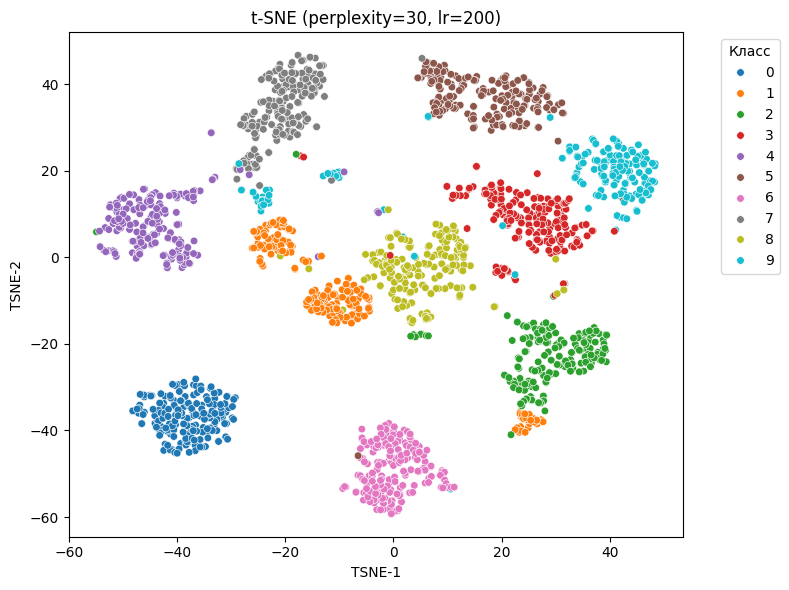

In [ ]:
tsne = TSNE(
    n_components=2,
    random_state=42,
    learning_rate=200
)

X_tsne = tsne.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=y, palette="tab10", s=30)
plt.title("t-SNE (perplexity=30, lr=200)")
plt.xlabel("TSNE-1")
plt.ylabel("TSNE-2")
plt.legend(title="Класс", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()


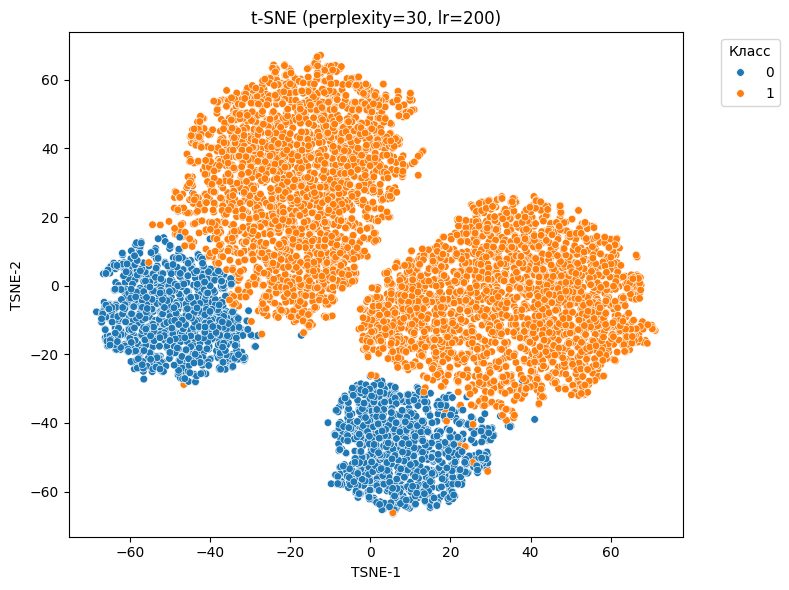

In [ ]:
tsne = TSNE(
    n_components=2,
    random_state=42,
    learning_rate=200,
    perplexity=50
)

X_phones_tsne = tsne.fit_transform(X_phones_scaled)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=X_phones_tsne[:, 0], y=X_phones_tsne[:, 1], hue=y_phones, palette="tab10", s=30)
plt.title("t-SNE (perplexity=30, lr=200)")
plt.xlabel("TSNE-1")
plt.ylabel("TSNE-2")
plt.legend(title="Класс", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()


In [ ]:
from sklearn.metrics import pairwise_distances

def separation_score(X_2d, y):
    D = pairwise_distances(X_2d) # попарное расстояние между всеми элементами
    same = D[y[:, None] == y[None, :]] # расстояния объектов с одинаковым классом
    diff = D[y[:, None] != y[None, :]] # расстояния объектов с разными классом
    return same.mean(), diff.mean(), diff.mean() / same.mean()

pca_same, pca_diff, pca_ratio = separation_score(X_pca, y)
tsne_same, tsne_diff, tsne_ratio = separation_score(X_tsne, y)

print("PCA:  среднее расстояние внутри класса =", pca_same,
      ", между классами =", pca_diff,
      ", ratio =", pca_ratio)
print("t-SNE: среднее расстояние внутри класса =", tsne_same,
      ", между классами =", tsne_diff,
      ", ratio =", tsne_ratio)


PCA:  среднее расстояние внутри класса = 2.468234399163824 , между классами = 4.76145615668781 , ratio = 1.9290939945982732
t-SNE: среднее расстояние внутри класса = 13.243144 , между классами = 54.21296 , ratio = 4.0936623


In [ ]:
phones_pca_same, phones_pca_diff, phones_pca_ratio = separation_score(X_phones_pca, np.array(y_phones))
phones_tsne_same, phones_tsne_diff, phones_tsne_ratio = separation_score(X_phones_tsne, np.array(y_phones))

print("PCA:  среднее расстояние внутри класса =", phones_pca_same,
      ", между классами =", phones_pca_diff,
      ", ratio =", phones_pca_ratio)
print("t-SNE: среднее расстояние внутри класса =", phones_tsne_same,
      ", между классами =", phones_tsne_diff,
      ", ratio =", phones_tsne_ratio)


PCA:  среднее расстояние внутри класса = 1.8733374782503454 , между классами = 3.1070017660557827 , ratio = 1.6585381983376812
t-SNE: среднее расстояние внутри класса = 47.928345 , между классами = 68.739494 , ratio = 1.4342139


Разделимость кластеров лучше выражена у PCA

Вычислить и отрисовать T-SNE с разным значением Perplexity

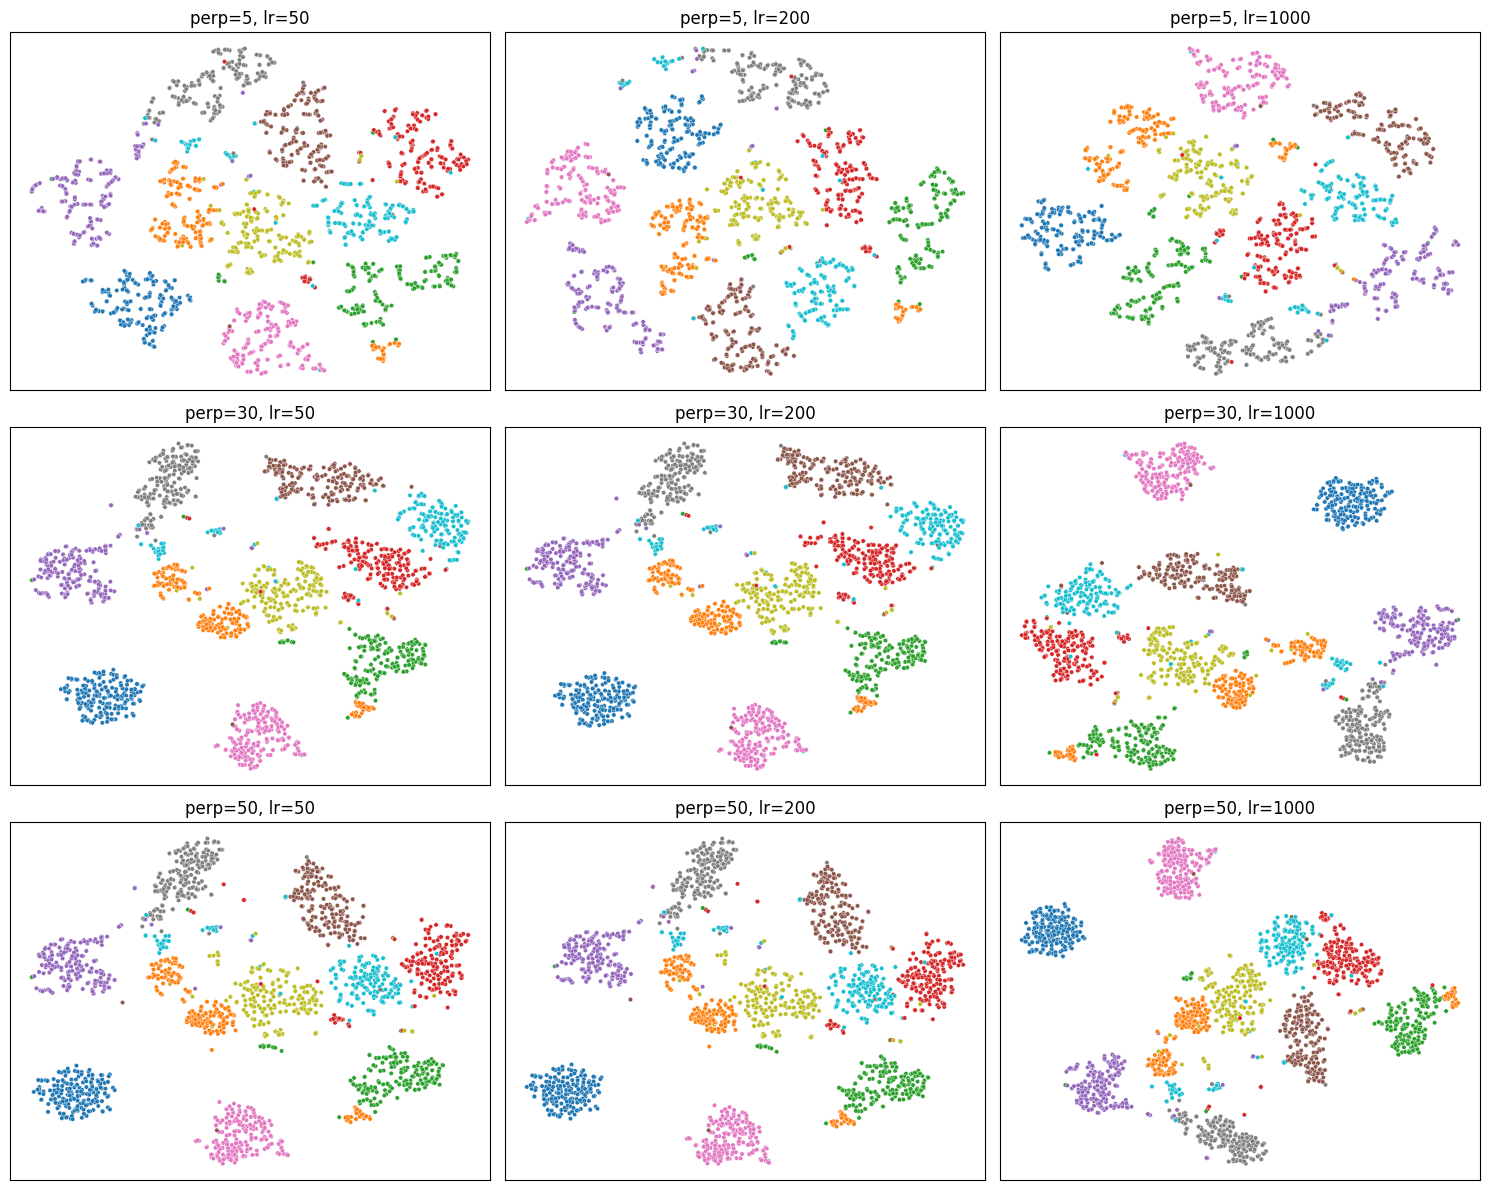

In [ ]:
perplexities = [5, 30, 50]
learning_rates = [50, 200, 1000]

fig, axes = plt.subplots(len(perplexities), len(learning_rates),
                         figsize=(5*len(learning_rates), 4*len(perplexities)))

for i, perp in enumerate(perplexities):
    for j, lr in enumerate(learning_rates):
        tsne = TSNE(
            perplexity=perp,
            learning_rate=lr,
            random_state=42
        )
        X_emb = tsne.fit_transform(X_scaled)
        ax = axes[i, j]
        sns.scatterplot(x=X_emb[:, 0], y=X_emb[:, 1],
                        hue=y, palette="tab10", s=10, ax=ax, legend=False)
        ax.set_title(f"perp={perp}, lr={lr}")
        ax.set_xticks([])
        ax.set_yticks([])

plt.tight_layout()
plt.show()


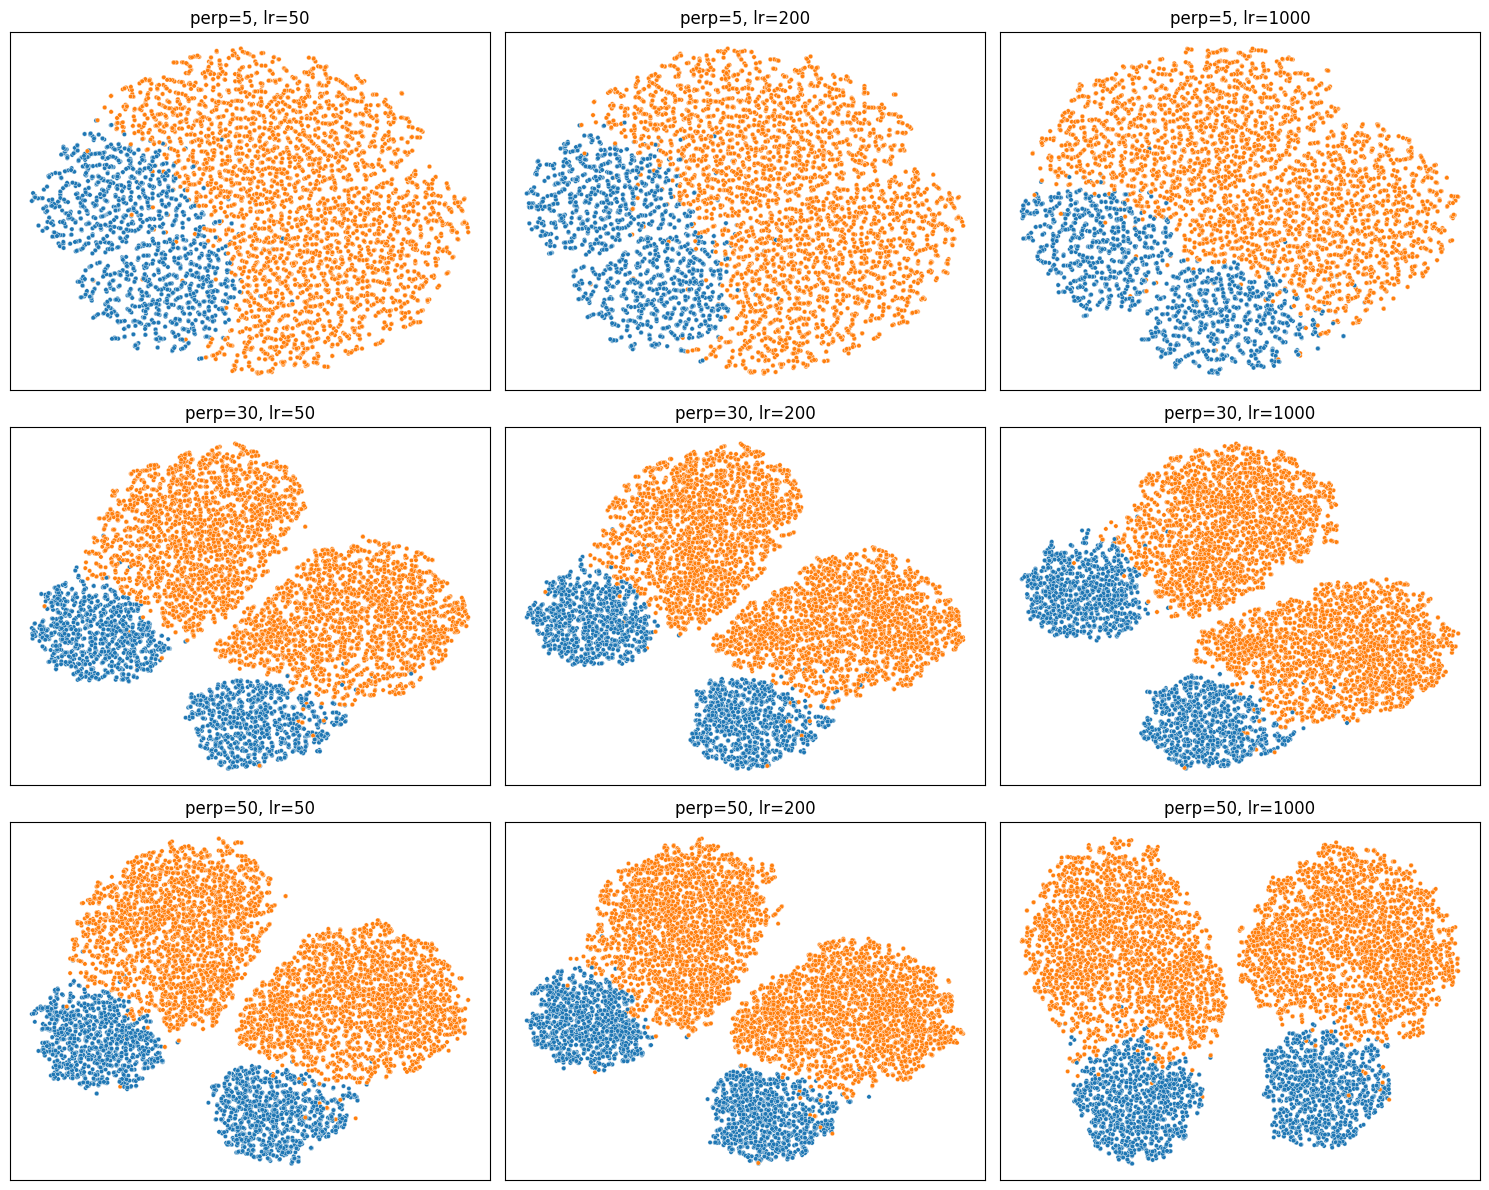

In [ ]:
perplexities = [5, 30, 50]
learning_rates = [50, 200, 1000]

fig, axes = plt.subplots(len(perplexities), len(learning_rates),
                         figsize=(5*len(learning_rates), 4*len(perplexities)))

for i, perp in enumerate(perplexities):
    for j, lr in enumerate(learning_rates):
        tsne = TSNE(
            perplexity=perp,
            learning_rate=lr,
            random_state=42
        )
        X_emb = tsne.fit_transform(X_phones_scaled)
        ax = axes[i, j]
        sns.scatterplot(x=X_emb[:, 0], y=X_emb[:, 1],
                        hue=y_phones, palette="tab10", s=10, ax=ax, legend=False)
        ax.set_title(f"perp={perp}, lr={lr}")
        ax.set_xticks([])
        ax.set_yticks([])

plt.tight_layout()
plt.show()


Видно, что с увеличением perplexity кластеры уплотняются. А скорость обучения влияет на расстояние между кластерами. Небольшие изменения параметров почти не влияют на кластеризацию.

Проанализируйте:

как меняется форма кластеров,

возникают ли “разрывы” или слияния при разных параметрах,

насколько стабилен рисунок при небольших изменениях параметров.

PCA: устойчивая структура
Для PCA параметров немного (по сути только число компонент), проекция при фиксированном random_state практически не меняется, что показывает устойчивость метода.

Можно показать, что при разных n_components (2, 3, больше) первые две компоненты остаются близкими, а общая структура мало меняется.

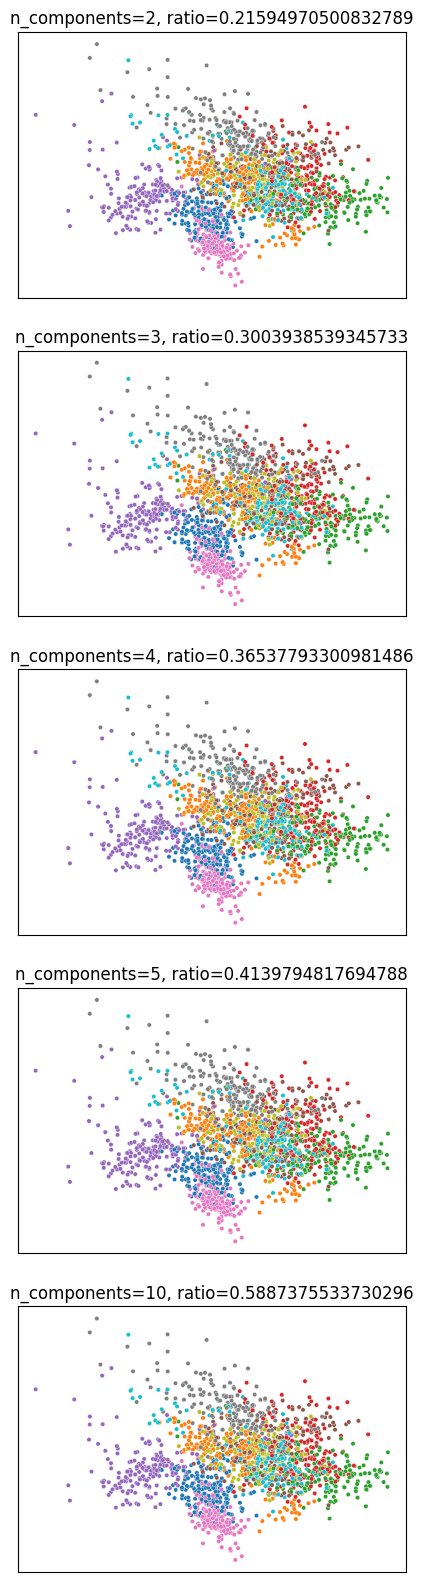

In [ ]:
n_components = [2, 3, 4, 5, 10]

fig, axes = plt.subplots(len(n_components), 1, figsize=(len(n_components), 4*len(n_components)))

for i, n in enumerate(n_components):
  pca = PCA(n_components=n, random_state=42)
  X_pca = pca.fit_transform(X_scaled)

  ax = axes[i]
  sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y, palette='tab10', s=10, ax=ax, legend=False)

  ax.set_title(f"n_components={n}, ratio={pca.explained_variance_ratio_.sum()}")
  ax.set_xticks([])
  ax.set_yticks([])


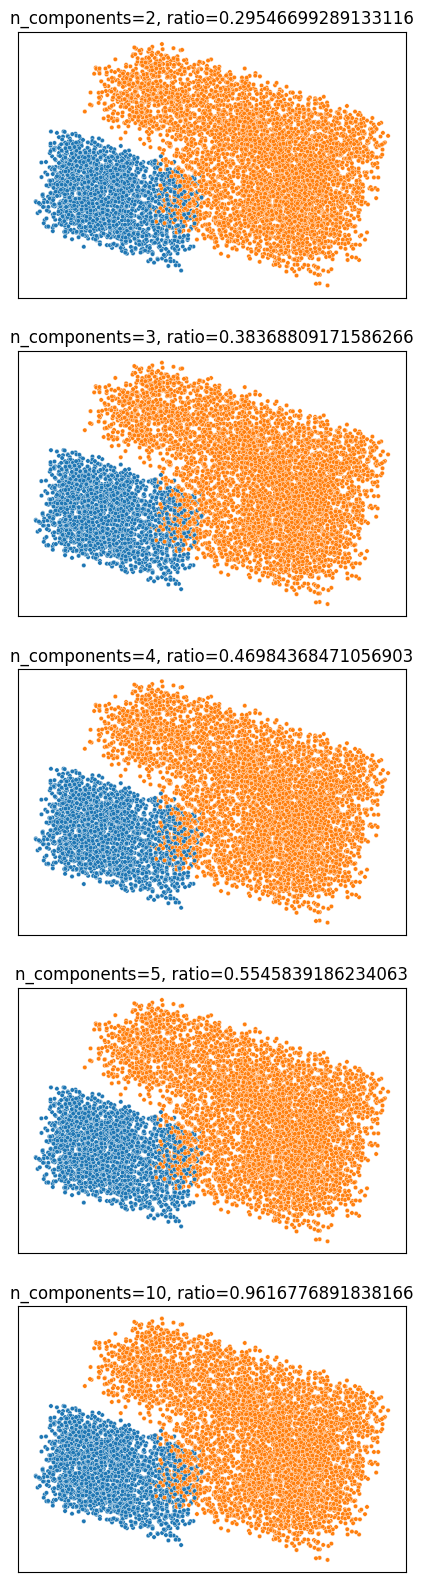

In [ ]:
n_components = [2, 3, 4, 5, 10]

fig, axes = plt.subplots(len(n_components), 1, figsize=(len(n_components), 4*len(n_components)))

for i, n in enumerate(n_components):
  pca = PCA(n_components=n, random_state=42)
  X_phones_pca = pca.fit_transform(X_phones_scaled)

  ax = axes[i]
  sns.scatterplot(x=X_phones_pca[:, 0], y=X_phones_pca[:, 1], hue=y_phones, palette='tab10', s=10, ax=ax, legend=False)

  ax.set_title(f"n_components={n}, ratio={pca.explained_variance_ratio_.sum()}")
  ax.set_xticks([])
  ax.set_yticks([])
